# ResNet50 Transfer Learning Baseline

ResNet50 pretrained on ImageNet is used as the first transfer-learning baseline for the cleaned skin-disease dataset. The objective is to establish a reproducible reference before evaluating more advanced architectures. Model fitting, early stopping, and checkpoint selection use only the training and validation subsets. The test subset remains frozen and is not used for predictions or model-selection decisions in this notebook.

## 1. Imports and Reproducibility Configuration

In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"PyTorch CUDA version: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
if CUDA_AVAILABLE:
    print(f"GPU: {GPU_NAME}")
    print(f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB")

PyTorch version: 2.13.0+cu132
CUDA available: True
PyTorch CUDA version: 13.2
Selected device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths

In [2]:
RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the raw dataset and processed manifests."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / RAW_RELATIVE_PATH).is_dir()
            and (candidate / "data" / "processed").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and data/processed."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
TORCH_CACHE_DIR = MODELS_DIR / "torch_cache"

for directory in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR, TORCH_CACHE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

torch.hub.set_dir(str(TORCH_CACHE_DIR))

MANIFEST_PATHS = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
missing_manifests = [path for path in MANIFEST_PATHS.values() if not path.is_file()]
if missing_manifests:
    missing_text = "\n".join(f"  - {path}" for path in missing_manifests)
    raise FileNotFoundError(
        "Processed manifests are missing. Execute "
        "notebooks/02_dataset_cleaning_and_split.ipynb first. Missing files:\n"
        f"{missing_text}"
    )

CHECKPOINT_PATH = MODELS_DIR / "resnet50_baseline_best.pth"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Model checkpoint: {CHECKPOINT_PATH}")

Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Model checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\resnet50_baseline_best.pth


## 3. Load and Validate Data Manifests

The split created in the preceding stage is loaded without reshuffling or reassigning any image. The test manifest is validated structurally but is not used to create a prediction loader.

In [3]:
manifests = {
    split_name: pd.read_csv(path)
    for split_name, path in MANIFEST_PATHS.items()
}
REQUIRED_COLUMNS = {"relative_path", "class_name", "class_id", "group_id"}

for split_name, manifest in manifests.items():
    missing_columns = REQUIRED_COLUMNS - set(manifest.columns)
    if missing_columns:
        raise ValueError(
            f"{MANIFEST_PATHS[split_name].name} is missing columns: {sorted(missing_columns)}"
        )
    if manifest["relative_path"].duplicated().any():
        raise ValueError(f"Duplicate paths exist within the {split_name} manifest.")
    if "split" in manifest.columns and not manifest["split"].eq(split_name).all():
        raise ValueError(f"The split column is inconsistent in {MANIFEST_PATHS[split_name].name}.")

all_paths = pd.concat(
    [
        manifest[["relative_path"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
if all_paths["relative_path"].duplicated().any():
    duplicated_paths = all_paths.loc[
        all_paths["relative_path"].duplicated(keep=False), "relative_path"
    ]
    raise ValueError(
        f"{duplicated_paths.nunique():,} image path(s) occur in more than one split."
    )

missing_images = [
    relative_path
    for relative_path in all_paths["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images):,} manifest image paths do not exist on disk."
    )

split_summary = pd.DataFrame(
    {
        "split": list(manifests),
        "images": [len(manifests[name]) for name in manifests],
    }
)
split_summary["percentage"] = 100 * split_summary["images"] / split_summary["images"].sum()
display(split_summary)

train_validation_distribution = pd.concat(
    [
        manifest.groupby(["class_id", "class_name"]).size().rename("images").reset_index().assign(split=split_name)
        for split_name, manifest in manifests.items()
        if split_name in {"train", "validation"}
    ],
    ignore_index=True,
)
train_validation_distribution["percentage_within_split"] = (
    100
    * train_validation_distribution["images"]
    / train_validation_distribution.groupby("split")["images"].transform("sum")
)
display(
    train_validation_distribution.sort_values(["class_id", "split"])
)

print(f"Training images: {len(manifests['train']):,}")
print(f"Validation images: {len(manifests['validation']):,}")
print(f"Frozen test images (structural validation only): {len(manifests['test']):,}")
print(f"Unique paths across all splits: {all_paths['relative_path'].nunique():,}")

,split,images,percentage
0,train,18491,70.009844
1,validation,3961,14.996971
2,test,3960,14.993185


,class_id,class_name,images,split,percentage_within_split
0,0,Eczema,1068,train,5.775783
10,0,Eczema,228,validation,5.756122
1,1,Melanoma,2195,train,11.870640
11,1,Melanoma,471,validation,11.890937
2,2,Atopic Dermatitis,804,train,4.348061
12,2,Atopic Dermatitis,171,validation,4.317092
3,3,Basal Cell Carcinoma (BCC),2323,train,12.562868
13,3,Basal Cell Carcinoma (BCC),497,validation,12.547337
4,4,Melanocytic Nevi (NV),5577,train,30.160619
14,4,Melanocytic Nevi (NV),1195,validation,30.169149


Training images: 18,491
Validation images: 3,961
Frozen test images (structural validation only): 3,960
Unique paths across all splits: 26,412


## 4. Class Mapping

Labels are read from manifest columns rather than inferred from directory ordering.

In [4]:
mapping_frames = []
for split_name, manifest in manifests.items():
    split_mapping = manifest[["class_id", "class_name"]].drop_duplicates()
    if split_mapping["class_id"].duplicated().any() or split_mapping["class_name"].duplicated().any():
        raise ValueError(f"The class mapping is not one-to-one in the {split_name} manifest.")
    mapping_frames.append(split_mapping.assign(split=split_name))

mapping_check = pd.concat(mapping_frames, ignore_index=True)
class_mapping_table = (
    mapping_check[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if mapping_check.groupby("split").size().nunique() != 1:
    raise ValueError("The manifests do not contain the same number of classes.")
if class_mapping_table["class_id"].tolist() != list(range(len(class_mapping_table))):
    raise ValueError("Class IDs are not contiguous from zero.")
for split_name, split_mapping in mapping_check.groupby("split"):
    observed = split_mapping[["class_id", "class_name"]].sort_values("class_id").reset_index(drop=True)
    if not observed.equals(class_mapping_table):
        raise ValueError(f"Class mapping differs in the {split_name} manifest.")

CLASS_ID_TO_NAME = dict(
    zip(class_mapping_table["class_id"], class_mapping_table["class_name"])
)
NUM_CLASSES = len(CLASS_ID_TO_NAME)
display(class_mapping_table)
print(f"Number of classes: {NUM_CLASSES}")

,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Number of classes: 10


## 5. Input Preprocessing

ResNet50 receives 224 × 224 inputs with ImageNet normalization. Training augmentation is deliberately moderate: conservative random cropping, horizontal reflection, small rotation, and mild color jitter. Validation preprocessing is deterministic. Raw image files are never altered or saved.

In [5]:
IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.80, 1.00),
            ratio=(0.90, 1.10),
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.10,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

## 6. Dataset and DataLoaders

In [6]:
class SkinDiseaseDataset(Dataset):
    """Load images and labels directly from a processed manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), row["relative_path"]


train_dataset = SkinDiseaseDataset(
    manifests["train"], PROJECT_ROOT, transform=train_transform
)
validation_dataset = SkinDiseaseDataset(
    manifests["validation"], PROJECT_ROOT, transform=validation_transform
)

BATCH_SIZE = 32
NUM_WORKERS = 0  # Safe for Windows and interactive Jupyter execution.
PIN_MEMORY = CUDA_AVAILABLE

# Reduce BATCH_SIZE to 16 and rerun if CUDA reports an out-of-memory error.
train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=train_generator,
    persistent_workers=NUM_WORKERS > 0,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")

Training batches: 578
Validation batches: 124
Batch size: 32
DataLoader workers: 0
Pinned memory: True


## 7. Data Sanity Check

A small transformed batch verifies image loading, labels, normalization reversal, and augmentation behavior. The display is not used for medical interpretation.

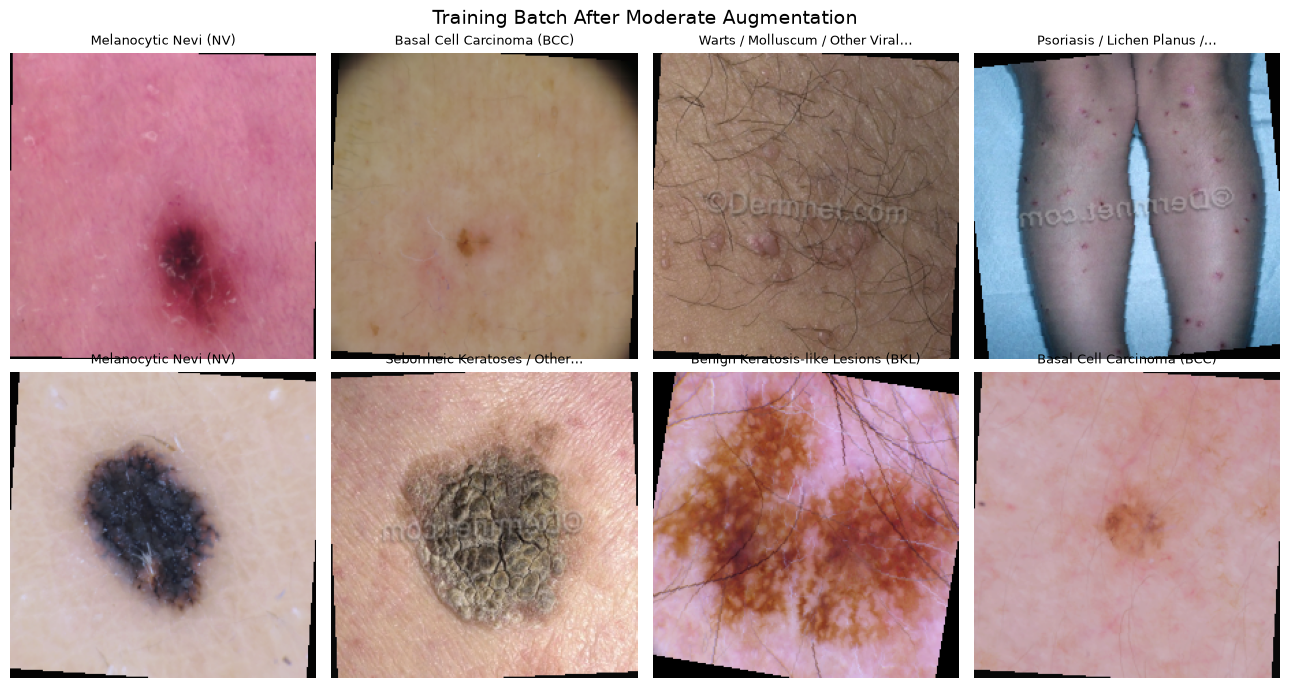

In [7]:
sample_images, sample_labels, _ = next(iter(train_loader))
train_generator.manual_seed(RANDOM_SEED)

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
display_count = min(8, len(sample_images))

fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for axis, image_tensor, label in zip(
    axes.flat, sample_images[:display_count], sample_labels[:display_count]
):
    image_for_display = (image_tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    axis.imshow(image_for_display.permute(1, 2, 0).numpy())
    axis.set_title(
        textwrap.shorten(CLASS_ID_TO_NAME[int(label)], width=35, placeholder="…"),
        fontsize=9,
    )
    axis.axis("off")
for axis in axes.flat[display_count:]:
    axis.axis("off")
fig.suptitle("Training Batch After Moderate Augmentation", fontsize=14)
fig.tight_layout()
plt.show()

## 8. ResNet50 Model and Baseline Configuration

ImageNet-1K V2 weights are loaded through the current torchvision weights API. The final fully connected layer is replaced for the manifest-derived number of classes.

In [8]:
PRETRAINED_WEIGHTS = ResNet50_Weights.DEFAULT
model = models.resnet50(weights=PRETRAINED_WEIGHTS)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
initial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

WARMUP_EPOCHS = 3
FINE_TUNE_MAX_EPOCHS = 18
WARMUP_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
CHECKPOINT_CRITERION = "validation_macro_f1"

TRAINING_CONFIGURATION = {
    "random_seed": RANDOM_SEED,
    "architecture": "ResNet50",
    "pretrained_weights": PRETRAINED_WEIGHTS.name,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "warmup_learning_rate": WARMUP_LEARNING_RATE,
    "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "fine_tune_max_epochs": FINE_TUNE_MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_criterion": CHECKPOINT_CRITERION,
    "torch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
}

print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Output classes: {NUM_CLASSES}")
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {initial_trainable_parameters:,}")

Pretrained weights: IMAGENET1K_V2
Output classes: 10
Total parameters: 23,528,522
Initially trainable parameters: 23,528,522


## 9. Training and Validation Functions

Cross-entropy loss is used without class weighting to preserve a simple primary baseline. CUDA automatic mixed precision is enabled when available. Validation macro F1 is the checkpoint and early-stopping criterion.

In [9]:
criterion = nn.CrossEntropyLoss()
AMP_ENABLED = DEVICE.type == "cuda"


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    freeze_backbone: bool,
):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    model.train()
    if freeze_backbone:
        for module in list(model.children())[:-1]:
            module.eval()

    running_loss = 0.0
    correct_predictions = 0
    sample_count = 0

    progress = tqdm(loader, desc="Training", unit="batch", leave=False)
    for images, labels, _ in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.detach().item() * batch_size
        correct_predictions += (logits.detach().argmax(dim=1) == labels).sum().item()
        sample_count += batch_size
        progress.set_postfix(
            loss=f"{running_loss / sample_count:.4f}",
            accuracy=f"{correct_predictions / sample_count:.3f}",
        )

    return {
        "loss": running_loss / sample_count,
        "accuracy": correct_predictions / sample_count,
    }


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device, description="Validation"):
    """Evaluate a model and return aggregate metrics plus CPU prediction arrays."""
    model.eval()
    running_loss = 0.0
    sample_count = 0
    targets = []
    predictions = []
    confidences = []
    relative_paths = []

    progress = tqdm(loader, desc=description, unit="batch", leave=False)
    for images, labels, paths in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        sample_count += batch_size
        targets.extend(labels.cpu().numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        relative_paths.extend(paths)

    targets = np.asarray(targets, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    confidences = np.asarray(confidences, dtype=np.float32)

    return {
        "loss": running_loss / sample_count,
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences,
        "relative_paths": relative_paths,
    }


def save_best_checkpoint(
    path: Path,
    model,
    epoch: int,
    stage: str,
    validation_metrics: dict,
):
    """Save a validation-selected checkpoint with reproducibility metadata."""
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "class_mapping": CLASS_ID_TO_NAME,
            "best_validation_macro_f1": validation_metrics["macro_f1"],
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "epoch": epoch,
            "stage": stage,
            "training_configuration": TRAINING_CONFIGURATION,
        },
        path,
    )


def load_model_checkpoint(path: Path, model, device):
    """Load a saved checkpoint and restore model parameters on the selected device."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()
    return checkpoint


def record_epoch(
    history,
    epoch: int,
    stage: str,
    training_metrics: dict,
    validation_metrics: dict,
    learning_rate: float,
):
    history.append(
        {
            "epoch": epoch,
            "stage": stage,
            "train_loss": training_metrics["loss"],
            "train_accuracy": training_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "learning_rate": learning_rate,
        }
    )
    pd.DataFrame(history).to_csv(
        REPORTS_DIR / "03_resnet50_training_history.csv",
        index=False,
        encoding="utf-8",
    )

## 10. Two-Stage Transfer Learning

Stage 1 freezes the pretrained backbone for three classifier warm-up epochs. Stage 2 unfreezes the complete network and applies lower-rate fine-tuning for at most 18 epochs. Early stopping during fine-tuning uses validation macro F1 with patience five. No validation or test class weights are introduced.

In [10]:
history = []
best_validation_macro_f1 = -np.inf
best_epoch = None
best_stage = None
global_epoch = 0

# Stage 1: classifier warm-up.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.fc.parameters():
    parameter.requires_grad = True

warmup_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 1 trainable parameters: {warmup_trainable_parameters:,}")

warmup_optimizer = AdamW(
    model.fc.parameters(),
    lr=WARMUP_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
warmup_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

for stage_epoch in range(1, WARMUP_EPOCHS + 1):
    global_epoch += 1
    print(f"Stage 1/2 — classifier warm-up epoch {stage_epoch}/{WARMUP_EPOCHS}")
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        warmup_optimizer,
        warmup_scaler,
        DEVICE,
        freeze_backbone=True,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = warmup_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "classifier_warmup",
        training_metrics,
        validation_metrics,
        learning_rate,
    )

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "classifier_warmup"
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}"
    )

# Stage 2: full-network fine-tuning.
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 2 trainable parameters: {fine_tune_trainable_parameters:,}")

fine_tune_optimizer = AdamW(
    model.parameters(),
    lr=FINE_TUNE_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
fine_tune_scheduler = ReduceLROnPlateau(
    fine_tune_optimizer,
    mode="max",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
)
fine_tune_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
epochs_without_improvement = 0

for stage_epoch in range(1, FINE_TUNE_MAX_EPOCHS + 1):
    global_epoch += 1
    print(f"Stage 2/2 — full fine-tuning epoch {stage_epoch}/{FINE_TUNE_MAX_EPOCHS}")
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        fine_tune_scaler,
        DEVICE,
        freeze_backbone=False,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = fine_tune_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "full_fine_tuning",
        training_metrics,
        validation_metrics,
        learning_rate,
    )
    fine_tune_scheduler.step(validation_metrics["macro_f1"])

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "full_fine_tuning"
        epochs_without_improvement = 0
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )
        improvement_note = "checkpoint updated"
    else:
        epochs_without_improvement += 1
        improvement_note = (
            f"no macro-F1 improvement for {epochs_without_improvement} epoch(s)"
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}; "
        f"{improvement_note}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            "Early stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} fine-tuning epochs without improvement."
        )
        break

training_history = pd.DataFrame(history)
training_history.to_csv(
    REPORTS_DIR / "03_resnet50_training_history.csv",
    index=False,
    encoding="utf-8",
)
display(training_history)
print(f"Best validation macro F1: {best_validation_macro_f1:.4f}")
print(f"Best epoch: {best_epoch} ({best_stage})")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")

Stage 1 trainable parameters: 20,490
Stage 1/2 — classifier warm-up epoch 1/3


Training:   0%|          | 0/578 [00:00<?, ?batch/s]

Validation:   0%|          | 0/124 [00:00<?, ?batch/s]

train loss=1.0067, train accuracy=0.6330, val loss=0.8376, val accuracy=0.6933, val macro F1=0.5872
Stage 1/2 — classifier warm-up epoch 2/3


Training:   0%|          | 0/578 [00:00<?, ?batch/s]

...

Training:   0%|          | 0/578 [00:00<?, ?batch/s]

Validation:   0%|          | 0/124 [00:00<?, ?batch/s]

train loss=0.0463, train accuracy=0.9841, val loss=0.6595, val accuracy=0.8531, val macro F1=0.7828; no macro-F1 improvement for 2 epoch(s)


,epoch,stage,train_loss,train_accuracy,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,learning_rate
0,1,classifier_warmup,1.006738,0.633011,0.837570,0.693259,0.581990,0.587173,0.0010
1,2,classifier_warmup,0.776567,0.715267,0.775861,0.712194,0.610756,0.615712,0.0010
2,3,classifier_warmup,0.712991,0.738846,0.750145,0.724565,0.612618,0.619333,0.0010
3,4,full_fine_tuning,0.680842,0.749121,0.561908,0.784650,0.693231,0.690025,0.0001
4,5,full_fine_tuning,0.438441,0.840138,0.510925,0.805100,0.722980,0.719575,0.0001
5,6,full_fine_tuning,0.325886,0.883673,0.497179,0.826306,0.748911,0.744634,0.0001
6,7,full_fine_tuning,0.240723,0.915040,0.502926,0.835900,0.767838,0.760192,0.0001
7,8,full_fine_tuning,0.178722,0.939430,0.492653,0.845998,0.771785,0.772051,0.0001
8,9,full_fine_tuning,0.138873,0.952517,0.563603,0.834133,0.756335,0.756043,0.0001
9,10,full_fine_tuning,0.118333,0.960197,0.557013,0.842464,0.769103,0.768031,0.0001


Best validation macro F1: 0.7869
Best epoch: 19 (full_fine_tuning)
Checkpoint saved to: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\resnet50_baseline_best.pth


## 11. Training Curves

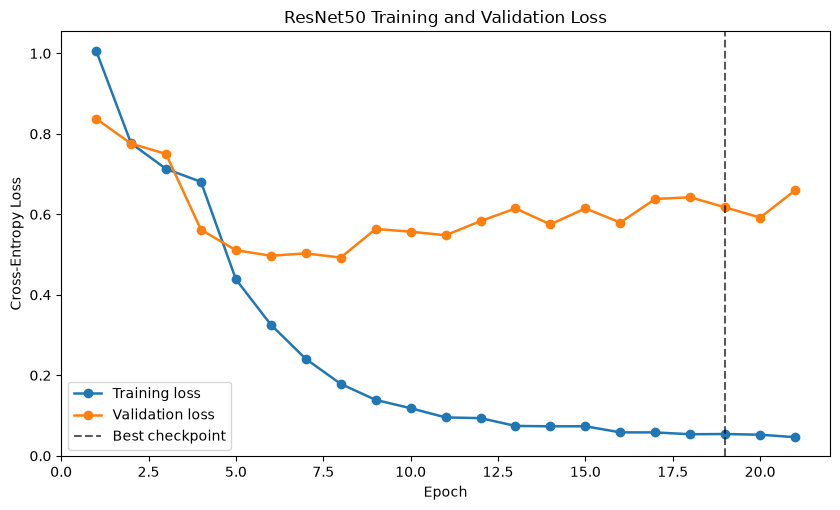

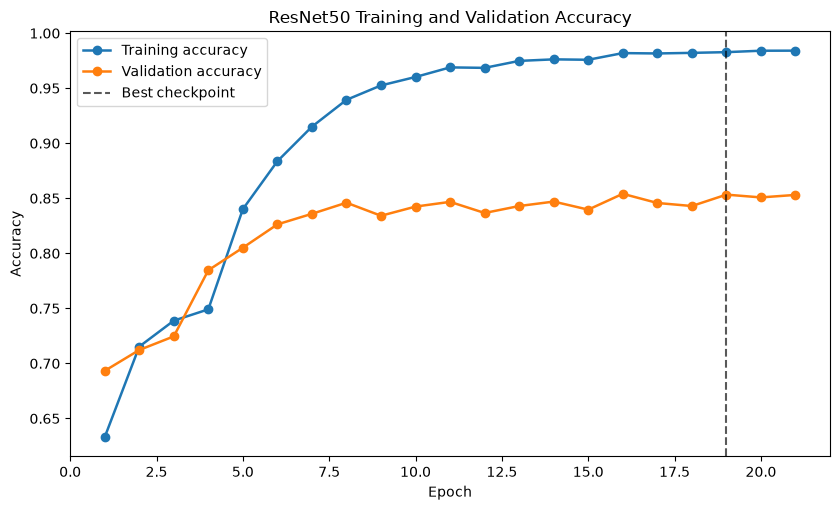

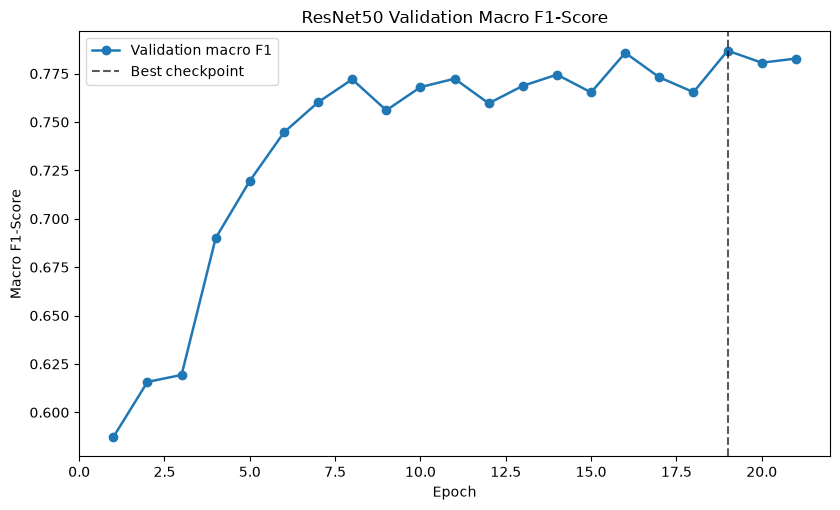

In [11]:
def save_curve(
    history_frame: pd.DataFrame,
    columns: list[str],
    labels: list[str],
    ylabel: str,
    title: str,
    output_path: Path,
):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for column, label in zip(columns, labels):
        ax.plot(
            history_frame["epoch"],
            history_frame[column],
            marker="o",
            linewidth=1.8,
            label=label,
        )
    ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.65, label="Best checkpoint")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


save_curve(
    training_history,
    ["train_loss", "val_loss"],
    ["Training loss", "Validation loss"],
    "Cross-Entropy Loss",
    "ResNet50 Training and Validation Loss",
    FIGURES_DIR / "03_resnet50_loss_curve.png",
)
save_curve(
    training_history,
    ["train_accuracy", "val_accuracy"],
    ["Training accuracy", "Validation accuracy"],
    "Accuracy",
    "ResNet50 Training and Validation Accuracy",
    FIGURES_DIR / "03_resnet50_accuracy_curve.png",
)
save_curve(
    training_history,
    ["val_macro_f1"],
    ["Validation macro F1"],
    "Macro F1-Score",
    "ResNet50 Validation Macro F1-Score",
    FIGURES_DIR / "03_resnet50_macro_f1_curve.png",
)

## 12. Best-Checkpoint Validation Evaluation

All subsequent analysis reloads the checkpoint selected by validation macro F1 rather than using the final training epoch.

In [12]:
checkpoint = load_model_checkpoint(CHECKPOINT_PATH, model, DEVICE)

if checkpoint["class_mapping"] != CLASS_ID_TO_NAME:
    raise ValueError("The checkpoint class mapping differs from the active manifest mapping.")

best_validation = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
    description="Best-checkpoint validation",
)
validation_targets = best_validation["targets"]
validation_predictions = best_validation["predictions"]

validation_metric_values = {
    "accuracy": accuracy_score(validation_targets, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        validation_targets, validation_predictions
    ),
    "macro_f1": f1_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "macro_precision": precision_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        validation_targets, validation_predictions, average="weighted", zero_division=0
    ),
}
validation_metrics_table = pd.DataFrame(
    {
        "metric": list(validation_metric_values),
        "value": list(validation_metric_values.values()),
    }
)
validation_metrics_table.to_csv(
    REPORTS_DIR / "03_resnet50_validation_metrics.csv",
    index=False,
    encoding="utf-8",
)

class_ids = class_mapping_table["class_id"].to_numpy()
per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        validation_targets,
        validation_predictions,
        labels=class_ids,
        zero_division=0,
    )
)
per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)
per_class_metrics.to_csv(
    REPORTS_DIR / "03_resnet50_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

print(
    f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
    f"({checkpoint['stage']})."
)
display(validation_metrics_table.style.format({"value": "{:.4f}"}))
display(
    per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)

Best-checkpoint validation:   0%|          | 0/124 [00:00<?, ?batch/s]

Loaded best checkpoint from epoch 19 (full_fine_tuning).


,metric,value
0,accuracy,0.8533
1,balanced_accuracy,0.7885
2,macro_f1,0.7869
3,macro_precision,0.7869
4,macro_recall,0.7885
5,weighted_f1,0.8533


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.7136,0.6886,0.7009,228
1,1,Melanoma,0.9957,0.9809,0.9882,471
2,2,Atopic Dermatitis,0.6075,0.6608,0.6331,171
3,3,Basal Cell Carcinoma (BCC),0.9360,0.9416,0.9388,497
4,4,Melanocytic Nevi (NV),0.9722,0.9665,0.9694,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.8265,0.8452,0.8357,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.6477,0.6610,0.6542,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.7197,0.8278,0.7700,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7156,0.6571,0.6851,245
9,9,Warts / Molluscum / Other Viral Infections,0.7349,0.6559,0.6932,279


## 13. Confusion Matrices

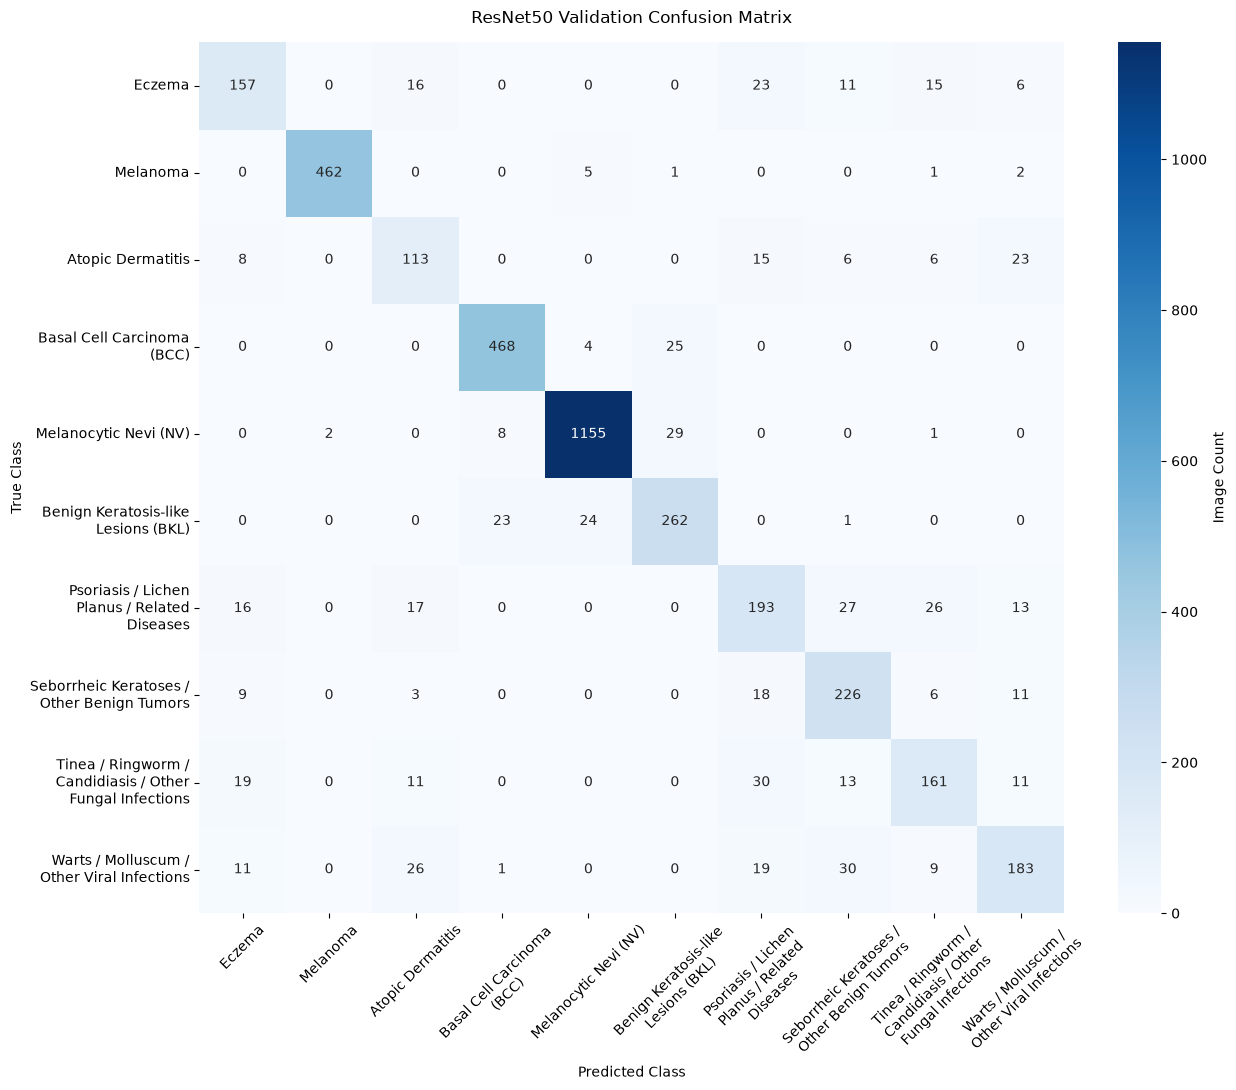

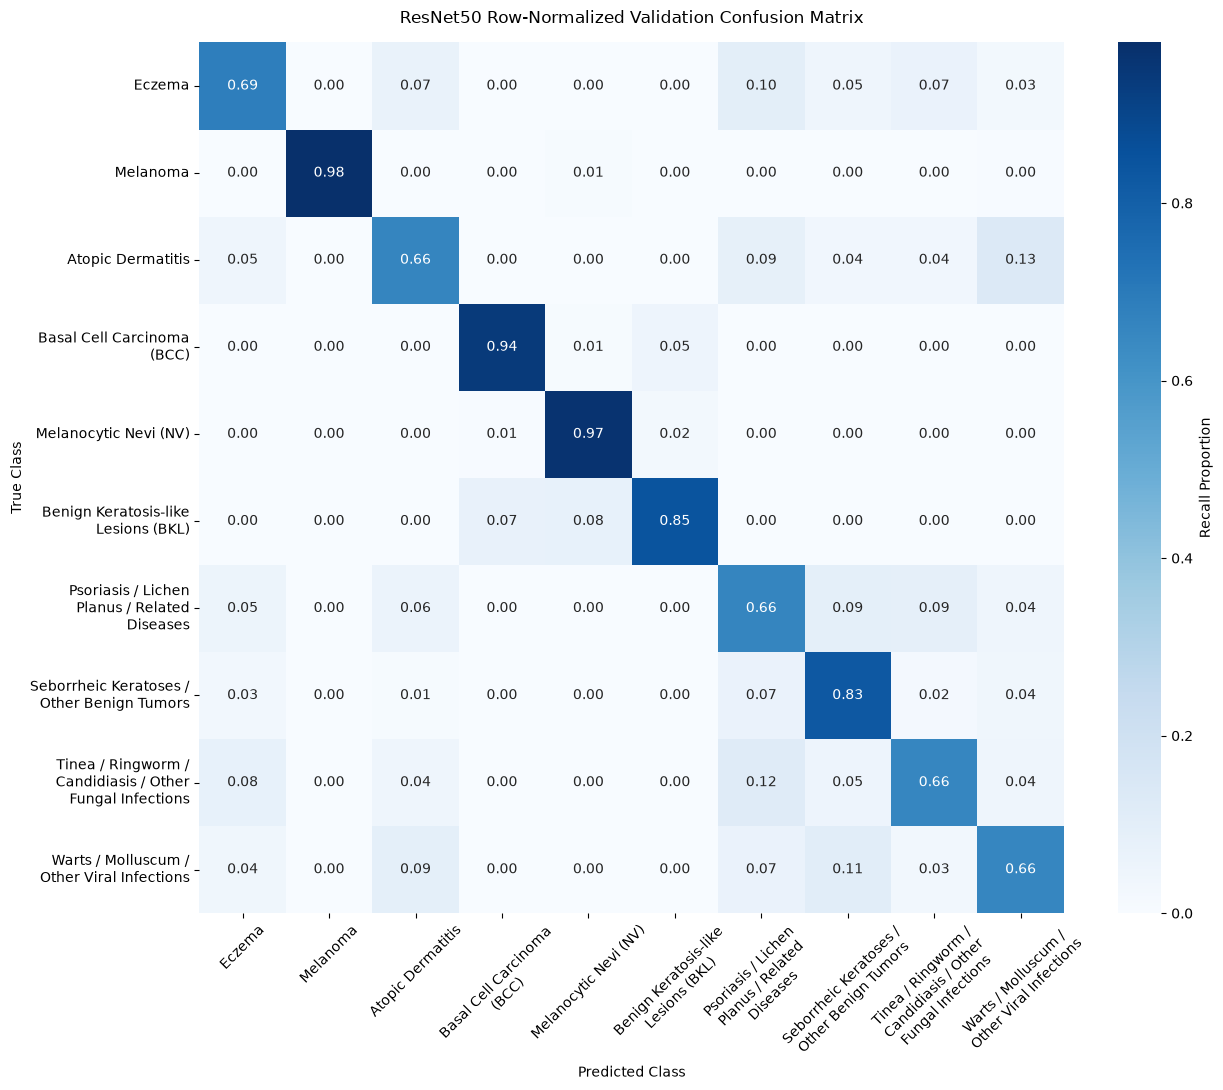

In [13]:
raw_confusion_matrix = confusion_matrix(
    validation_targets, validation_predictions, labels=class_ids
)
normalized_confusion_matrix = confusion_matrix(
    validation_targets,
    validation_predictions,
    labels=class_ids,
    normalize="true",
)
display_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24) for class_id in class_ids
]


def plot_confusion_matrix(matrix, title, output_path, value_format, colorbar_label):
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=value_format,
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    raw_confusion_matrix,
    "ResNet50 Validation Confusion Matrix",
    FIGURES_DIR / "03_resnet50_confusion_matrix.png",
    "d",
    "Image Count",
)
plot_confusion_matrix(
    normalized_confusion_matrix,
    "ResNet50 Row-Normalized Validation Confusion Matrix",
    FIGURES_DIR / "03_resnet50_confusion_matrix_normalized.png",
    ".2f",
    "Recall Proportion",
)

## 14. Error Analysis

The analysis below describes observed validation errors without inferring clinical causes.

In [14]:
highest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmax()]
lowest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmin()]
highest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmax()]
lowest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmin()]

off_diagonal_confusions = raw_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_confusions, 0)
confusion_records = []
for true_index, predicted_index in zip(
    *np.where(off_diagonal_confusions > 0)
):
    confusion_records.append(
        {
            "true_class": CLASS_ID_TO_NAME[int(class_ids[true_index])],
            "predicted_class": CLASS_ID_TO_NAME[int(class_ids[predicted_index])],
            "image_count": int(off_diagonal_confusions[true_index, predicted_index]),
        }
    )
frequent_confusions = pd.DataFrame(
    confusion_records,
    columns=["true_class", "predicted_class", "image_count"],
).sort_values(
    ["image_count", "true_class", "predicted_class"],
    ascending=[False, True, True],
    ignore_index=True,
)
if frequent_confusions.empty:
    most_common_confusion = {
        "true_class": "none",
        "predicted_class": "none",
        "image_count": 0,
    }
else:
    most_common_confusion = frequent_confusions.iloc[0]

print(
    f"Highest validation recall: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest validation recall: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest validation F1: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest validation F1: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
print("Most frequent directed confusion pairs:")
display(frequent_confusions.head(10))

Highest validation recall: Melanoma (0.9809)
Lowest validation recall: Warts / Molluscum / Other Viral Infections (0.6559)
Highest validation F1: Melanoma (0.9882)
Lowest validation F1: Atopic Dermatitis (0.6331)
Most frequent directed confusion pairs:


,true_class,predicted_class,image_count
0,Tinea / Ringworm / Candidiasis / Other Fungal ...,Psoriasis / Lichen Planus / Related Diseases,30
1,Warts / Molluscum / Other Viral Infections,Seborrheic Keratoses / Other Benign Tumors,30
2,Melanocytic Nevi (NV),Benign Keratosis-like Lesions (BKL),29
3,Psoriasis / Lichen Planus / Related Diseases,Seborrheic Keratoses / Other Benign Tumors,27
4,Psoriasis / Lichen Planus / Related Diseases,Tinea / Ringworm / Candidiasis / Other Fungal ...,26
5,Warts / Molluscum / Other Viral Infections,Atopic Dermatitis,26
6,Basal Cell Carcinoma (BCC),Benign Keratosis-like Lesions (BKL),25
7,Benign Keratosis-like Lesions (BKL),Melanocytic Nevi (NV),24
8,Atopic Dermatitis,Warts / Molluscum / Other Viral Infections,23
9,Benign Keratosis-like Lesions (BKL),Basal Cell Carcinoma (BCC),23


## 15. Confidence Analysis

Softmax confidence is summarized separately for correct and incorrect validation predictions. These values describe the model output distribution and are not a calibration assessment.

Average confidence for correct predictions: 0.9668
Average confidence for incorrect predictions: 0.8025


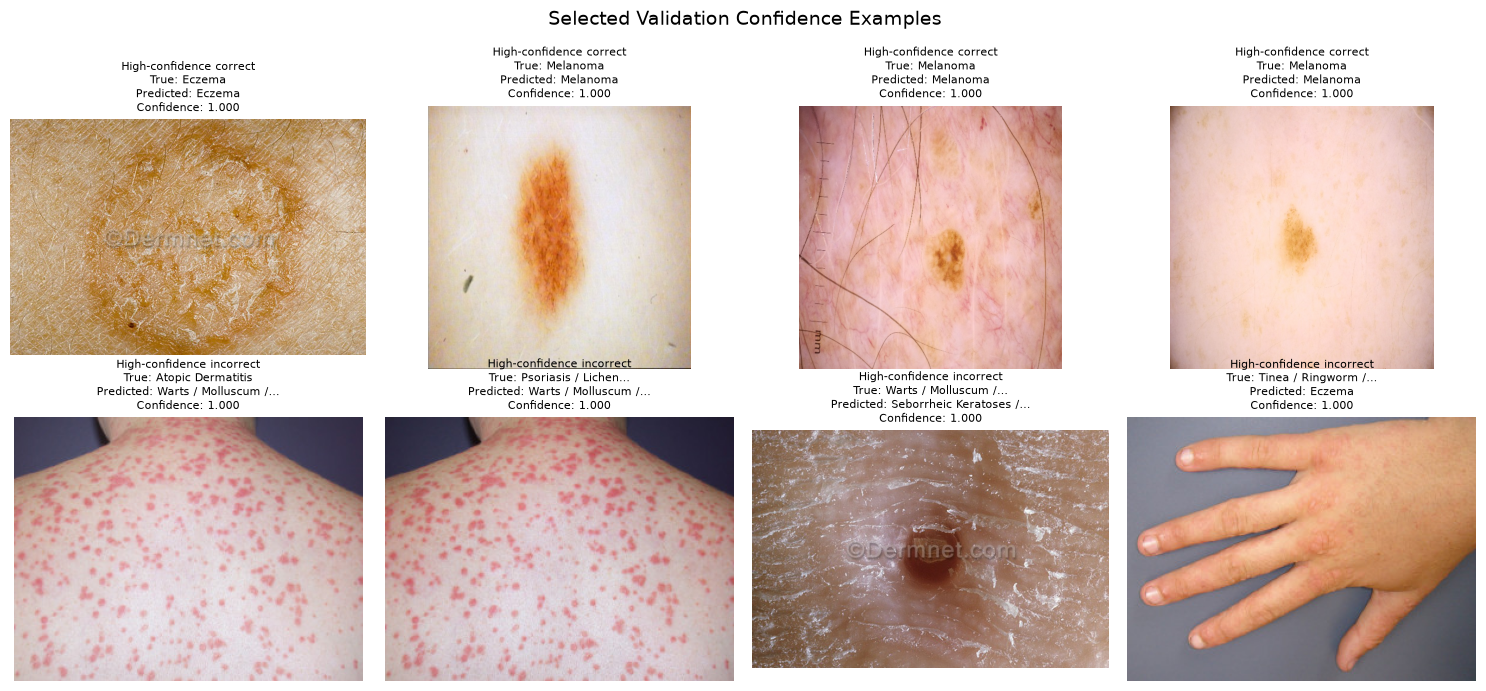

In [15]:
validation_predictions_table = pd.DataFrame(
    {
        "relative_path": best_validation["relative_paths"],
        "true_class_id": validation_targets,
        "predicted_class_id": validation_predictions,
        "confidence": best_validation["confidences"],
    }
)
validation_predictions_table["correct"] = (
    validation_predictions_table["true_class_id"]
    == validation_predictions_table["predicted_class_id"]
)
validation_predictions_table["true_class"] = validation_predictions_table[
    "true_class_id"
].map(CLASS_ID_TO_NAME)
validation_predictions_table["predicted_class"] = validation_predictions_table[
    "predicted_class_id"
].map(CLASS_ID_TO_NAME)

correct_confidence = validation_predictions_table.loc[
    validation_predictions_table["correct"], "confidence"
].mean()
incorrect_confidence = validation_predictions_table.loc[
    ~validation_predictions_table["correct"], "confidence"
].mean()

print(f"Average confidence for correct predictions: {correct_confidence:.4f}")
print(f"Average confidence for incorrect predictions: {incorrect_confidence:.4f}")

confidence_examples = pd.concat(
    [
        validation_predictions_table.loc[validation_predictions_table["correct"]]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence correct"),
        validation_predictions_table.loc[~validation_predictions_table["correct"]]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence incorrect"),
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), squeeze=False)
for axis, (_, row) in zip(axes.flat, confidence_examples.iterrows()):
    with Image.open(PROJECT_ROOT / row["relative_path"]) as image:
        image_for_display = ImageOps.exif_transpose(image).convert("RGB")
        axis.imshow(image_for_display)
    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {textwrap.shorten(row['true_class'], 24, placeholder='…')}\n"
        f"Predicted: {textwrap.shorten(row['predicted_class'], 24, placeholder='…')}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(confidence_examples):]:
    axis.axis("off")
fig.suptitle("Selected Validation Confidence Examples", fontsize=14)
fig.tight_layout()
plt.show()

## 16. Test Set Policy

The test manifest was checked only for schema, class mapping, path uniqueness, file existence, and size. No test dataset loader, predictions, accuracy, F1-score, or confusion matrix are produced. The test subset remains frozen until architecture selection and model-development decisions are complete.

## ResNet50 Baseline Summary

In [16]:
summary_markdown = f"""
- **Best checkpoint epoch:** {checkpoint['epoch']} ({checkpoint['stage'].replace('_', ' ')})
- **Validation accuracy:** {validation_metric_values['accuracy']:.4f}
- **Validation balanced accuracy:** {validation_metric_values['balanced_accuracy']:.4f}
- **Validation macro F1:** {validation_metric_values['macro_f1']:.4f}
- **Validation macro precision:** {validation_metric_values['macro_precision']:.4f}
- **Validation macro recall:** {validation_metric_values['macro_recall']:.4f}
- **Strongest class by validation F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest class by validation F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most common directed confusion:** true {most_common_confusion['true_class']} predicted as {most_common_confusion['predicted_class']} ({int(most_common_confusion['image_count'])} images)
"""
display(Markdown(summary_markdown))


- **Best checkpoint epoch:** 19 (full fine tuning)
- **Validation accuracy:** 0.8533
- **Validation balanced accuracy:** 0.7885
- **Validation macro F1:** 0.7869
- **Validation macro precision:** 0.7869
- **Validation macro recall:** 0.7885
- **Strongest class by validation F1:** Melanoma (0.9882)
- **Weakest class by validation F1:** Atopic Dermatitis (0.6331)
- **Most common directed confusion:** true Tinea / Ringworm / Candidiasis / Other Fungal Infections predicted as Psoriasis / Lichen Planus / Related Diseases (30 images)


### Interpretation

In [17]:
best_history_row = training_history.loc[
    training_history["epoch"] == checkpoint["epoch"]
].iloc[0]
first_history_row = training_history.iloc[0]
training_validation_gap = (
    best_history_row["train_accuracy"] - validation_metric_values["accuracy"]
)
per_class_f1_range = (
    per_class_metrics["f1_score"].max() - per_class_metrics["f1_score"].min()
)
support_f1_spearman = per_class_metrics["support"].corr(
    per_class_metrics["f1_score"], method="spearman"
)

if training_validation_gap > 0.10:
    fit_interpretation = (
        "The training–validation accuracy gap at the selected epoch is notable and is "
        "compatible with overfitting, although validation-selected checkpointing limits "
        "the effect on the reported baseline."
    )
elif training_validation_gap > 0.03:
    fit_interpretation = (
        "A modest training–validation accuracy gap is present at the selected epoch, "
        "indicating some overfitting pressure."
    )
else:
    fit_interpretation = (
        "The selected epoch does not show a large training–validation accuracy gap, so "
        "the recorded curves provide no strong evidence of overfitting at that point."
    )

if support_f1_spearman > 0.30:
    imbalance_interpretation = (
        "Per-class support and F1 show a positive rank association, consistent with class "
        "frequency contributing to uneven performance; this association does not establish causation."
    )
elif support_f1_spearman < -0.30:
    imbalance_interpretation = (
        "Per-class support and F1 show a negative rank association in this validation result, "
        "so class frequency alone does not explain the observed class-level differences."
    )
else:
    imbalance_interpretation = (
        "The rank association between per-class support and F1 is weak; class imbalance alone "
        "does not explain the observed class-level differences."
    )

interpretation_markdown = f"""
Validation macro F1 changed from {first_history_row['val_macro_f1']:.4f} in the first warm-up epoch to a best value of {validation_metric_values['macro_f1']:.4f} at epoch {checkpoint['epoch']}. At the selected epoch, training accuracy was {best_history_row['train_accuracy']:.4f} and validation accuracy was {validation_metric_values['accuracy']:.4f}, a difference of {training_validation_gap:.4f}. {fit_interpretation}

Per-class F1 spans {per_class_f1_range:.4f}, while the Spearman association between validation support and per-class F1 is {support_f1_spearman:.3f}. {imbalance_interpretation} ResNet50 therefore provides a quantified reference for subsequent controlled experiments, not evidence of clinical reliability. Generalization to independent clinical populations cannot be inferred from this validation subset. Heterogeneous acquisition sources, image styles, and visible artifacts identified during the dataset audit may provide shortcut cues and remain important limitations.
"""
display(Markdown(interpretation_markdown))


Validation macro F1 changed from 0.5872 in the first warm-up epoch to a best value of 0.7869 at epoch 19. At the selected epoch, training accuracy was 0.9827 and validation accuracy was 0.8533, a difference of 0.1294. The training–validation accuracy gap at the selected epoch is notable and is compatible with overfitting, although validation-selected checkpointing limits the effect on the reported baseline.

Per-class F1 spans 0.3552, while the Spearman association between validation support and per-class F1 is 0.782. Per-class support and F1 show a positive rank association, consistent with class frequency contributing to uneven performance; this association does not establish causation. ResNet50 therefore provides a quantified reference for subsequent controlled experiments, not evidence of clinical reliability. Generalization to independent clinical populations cannot be inferred from this validation subset. Heterogeneous acquisition sources, image styles, and visible artifacts identified during the dataset audit may provide shortcut cues and remain important limitations.


### Next Steps

Subsequent experiments may investigate class-imbalance handling, stronger but clinically appropriate augmentation, higher input resolution, EfficientNet, ConvNeXt, transformer-based models, focused hyperparameter tuning, and explainability methods such as Grad-CAM. These extensions are intentionally excluded from the baseline.

## Reproducibility Summary

In [18]:
configuration_summary = pd.DataFrame(
    {
        "configuration_item": list(TRAINING_CONFIGURATION),
        "value": list(TRAINING_CONFIGURATION.values()),
    }
)
display(configuration_summary)
print(f"Completed epochs: {len(training_history)}")
print(f"Best checkpoint: {CHECKPOINT_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print("Test-set predictions generated: False")

,configuration_item,value
0,random_seed,42
1,architecture,ResNet50
2,pretrained_weights,IMAGENET1K_V2
3,image_size,224
4,batch_size,32
5,optimizer,AdamW
6,warmup_learning_rate,0.001
7,fine_tune_learning_rate,0.0001
8,weight_decay,0.0001
9,warmup_epochs,3


Completed epochs: 21
Best checkpoint: models/resnet50_baseline_best.pth
Test-set predictions generated: False
